# module 1

In [1]:
import scanpy as sc

adata = sc.read_10x_mtx(
    'data/filtered_gene_bc_matrices/hg19/',
    var_names='gene_symbols'
)
adata.var_names_make_unique()
print(adata)

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'


In [2]:
# ミトコンドリア遺伝子の識別
adata.var['mt'] = adata.var_names.str.startswith('MT-')

# QC 指標の計算
sc.pp.calculate_qc_metrics(
    adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True
)

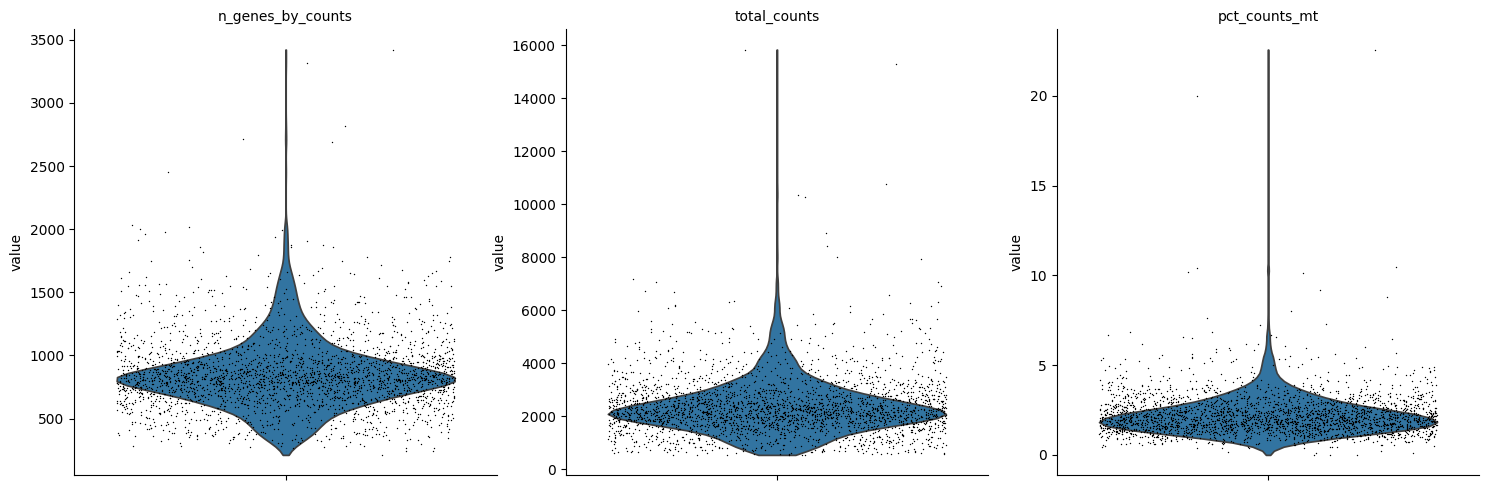

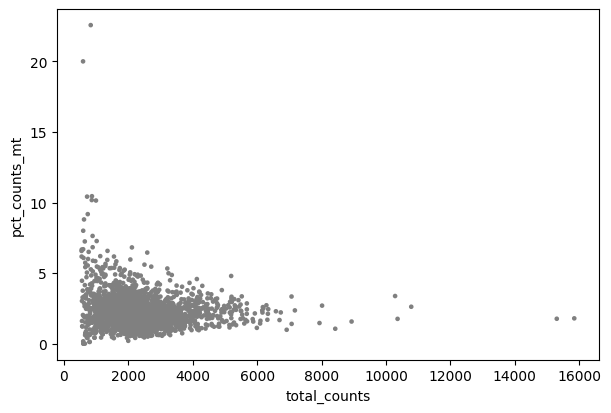

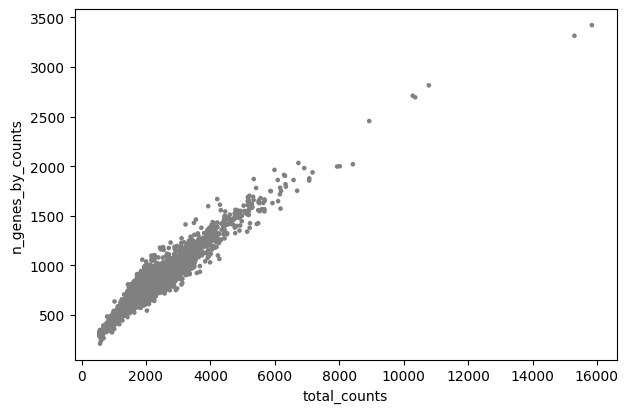

/Users/iwao/Docs/study-sc-rna-seq/.venv/lib/python3.13/site-packages/scanpy/preprocessing/_simple.py:279: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var["n_cells"] = number


In [3]:
# 可視化
sc.pl.violin(
    adata,
    ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'],
    jitter=0.4, multi_panel=True
)
sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt')
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts')

# フィルタリング
adata = adata[adata.obs.n_genes_by_counts < 2500, :]
adata = adata[adata.obs.pct_counts_mt < 5, :]
sc.pp.filter_genes(adata, min_cells=3)

## モジュール 2：正規化と高変動遺伝子選択

In [4]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata  # 正規化済みデータを保存

In [5]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
print(f"HVG 数: {adata.var.highly_variable.sum()}")  # 通常 2,000〜4,000
adata = adata[:, adata.var.highly_variable]

HVG 数: 1826


In [6]:
sc.pp.scale(adata, max_value=10)


/opt/homebrew/Cellar/python@3.13/3.13.15/Frameworks/Python.framework/Versions/3.13/lib/python3.13/functools.py:934: UserWarning: Received a view of an AnnData. Making a copy.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Cellar/python@3.13/3.13.15/Frameworks/Python.framework/Versions/3.13/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


## モジュール 3：次元削減 — PCA と UMAP の数理


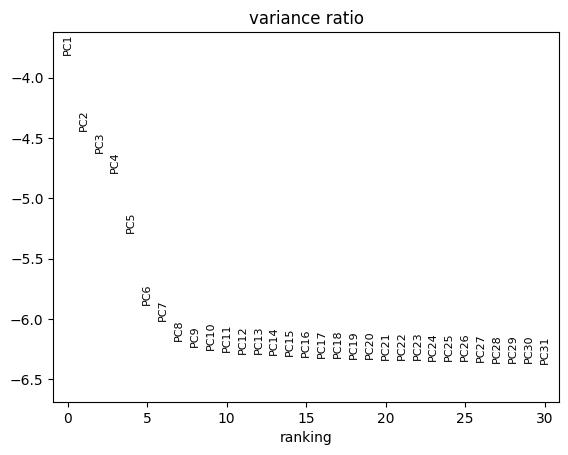

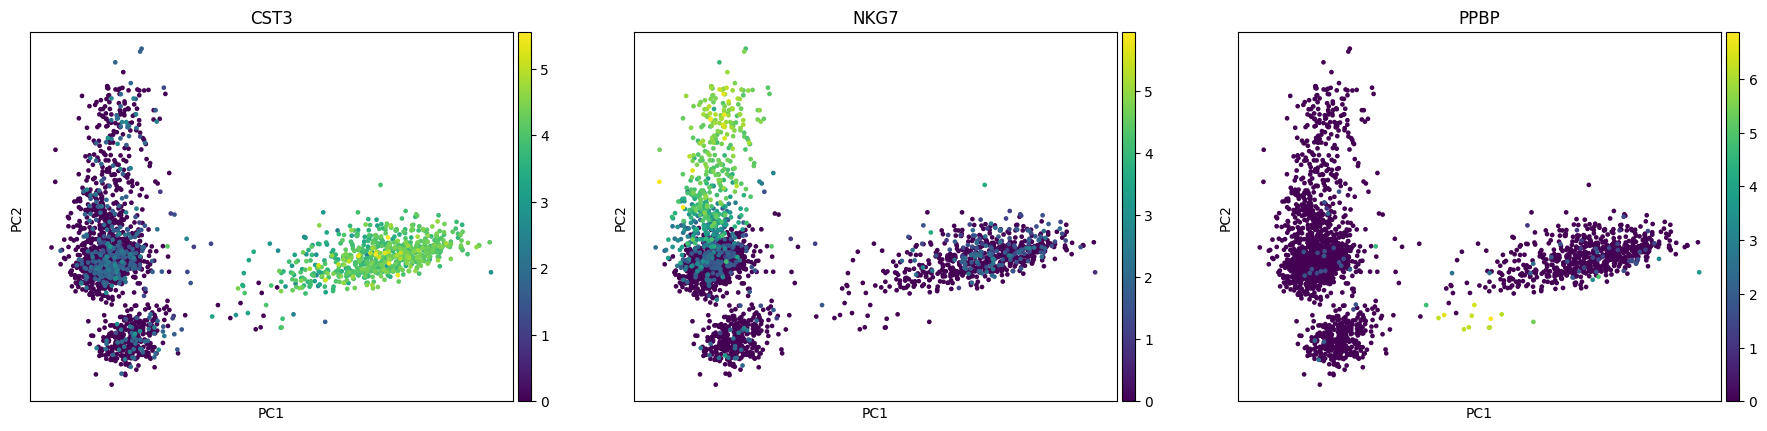

In [7]:
sc.tl.pca(adata, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata, log=True)  # elbow plot で PC 数を決定
sc.pl.pca(adata, color=['CST3', 'NKG7', 'PPBP'])

In [8]:
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40)


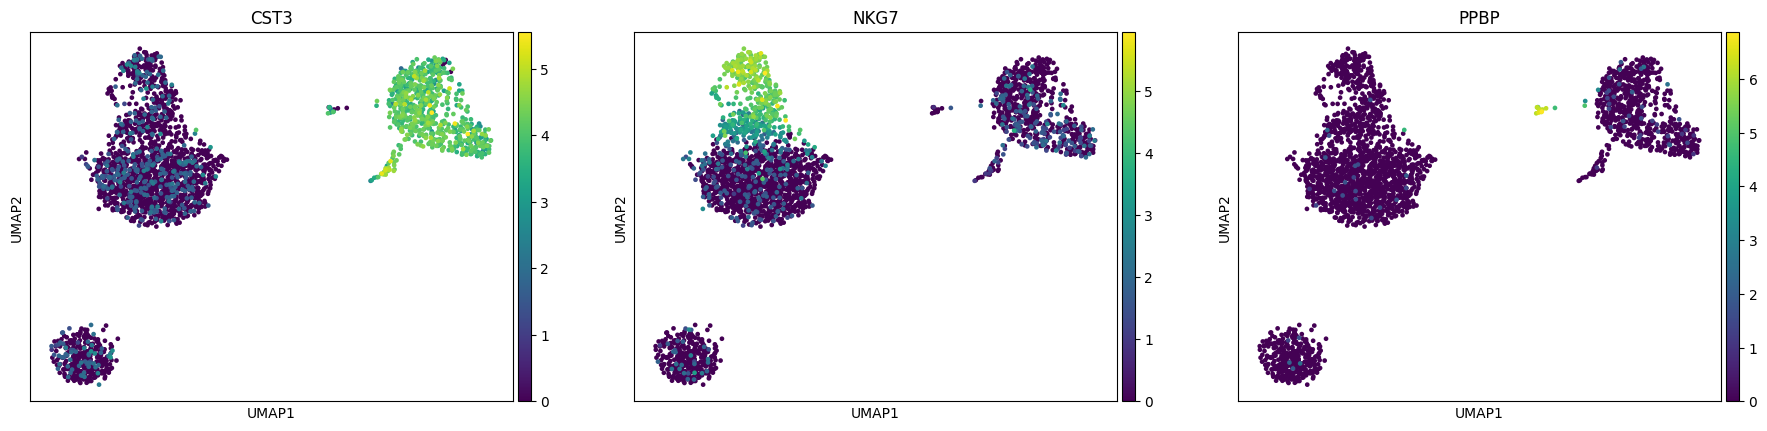

In [9]:
sc.tl.umap(adata)
sc.pl.umap(adata, color=['CST3', 'NKG7', 'PPBP'])

## モジュール 4：クラスタリングとグラフ分割


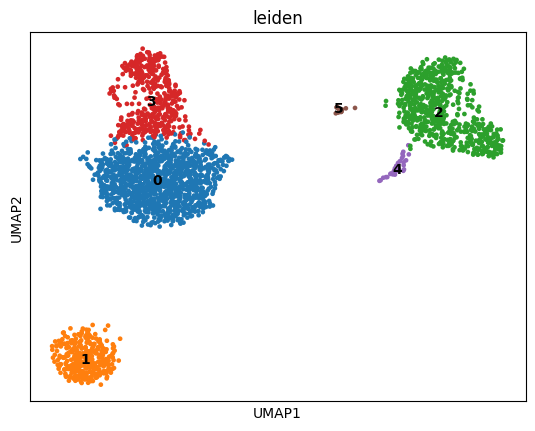

In [10]:
# igraph 実装（将来の既定）を明示する．n_iterations=2 は Leiden の反復回数，igraph 実装は無向グラフのみ対応
sc.tl.leiden(adata, resolution=0.5, flavor='igraph', n_iterations=2, directed=False)
sc.pl.umap(adata, color=['leiden'], legend_loc='on data')


## モジュール 5：細胞型アノテーション — マーカー遺伝子と仮説検定


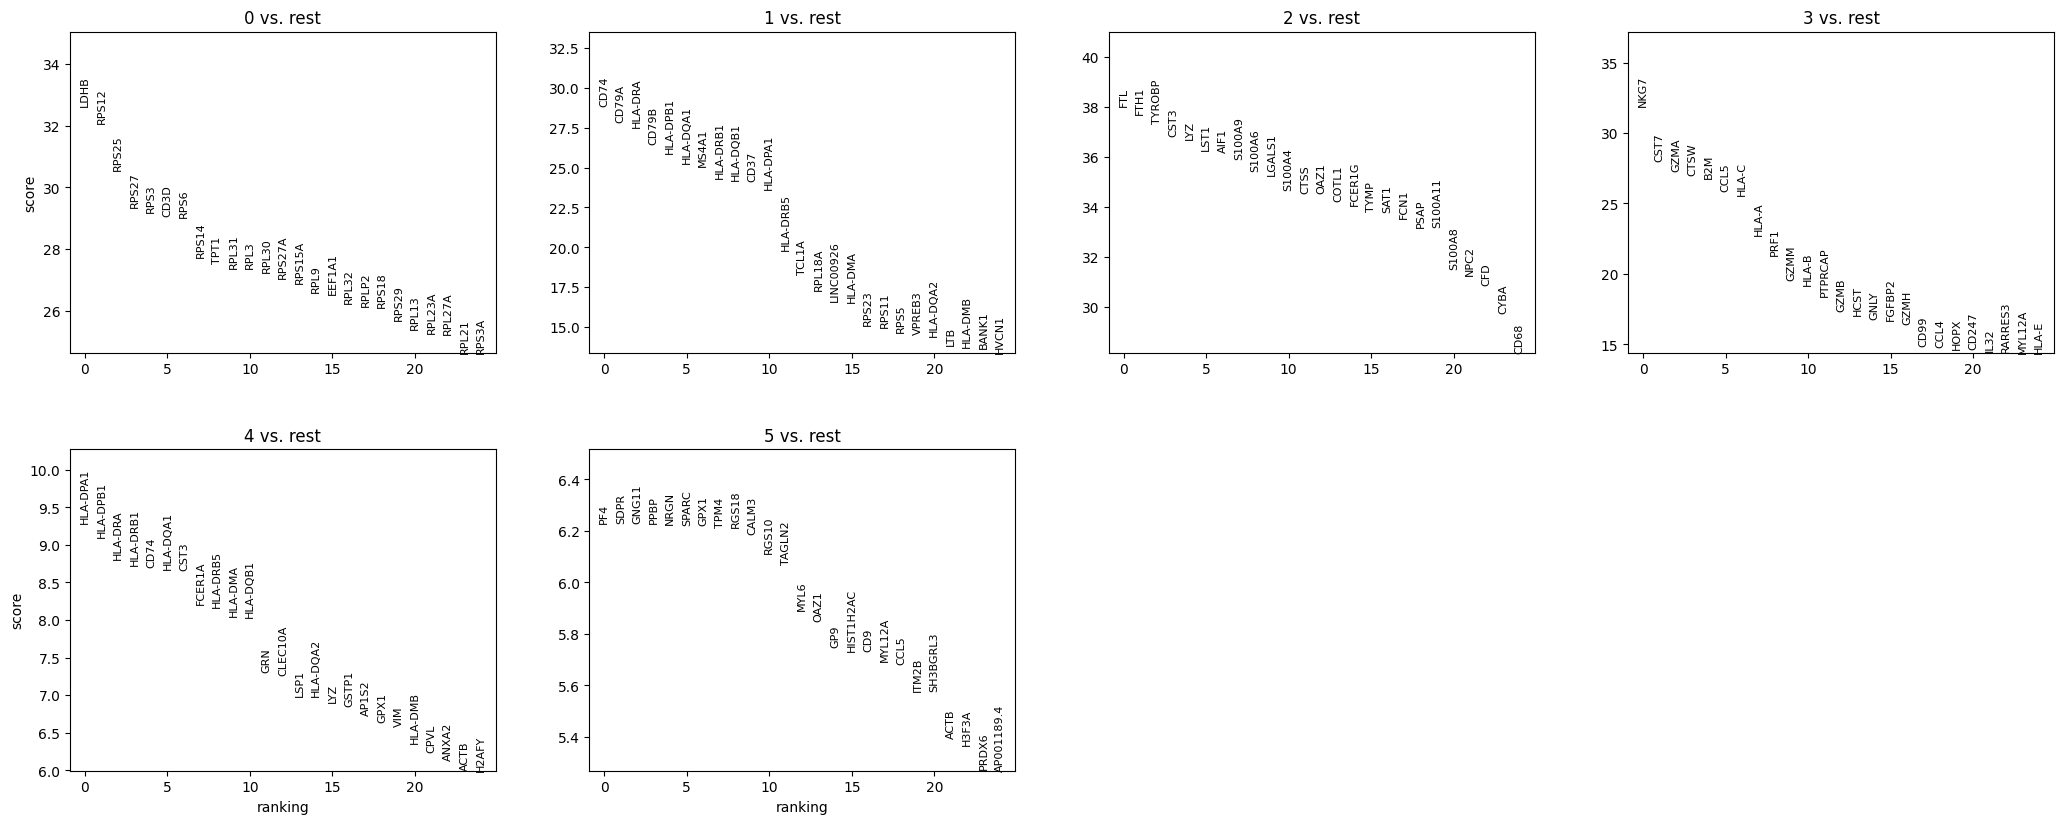

In [11]:

sc.tl.rank_genes_groups(adata, 'leiden', method='wilcoxon')
sc.pl.rank_genes_groups(adata, n_genes=25, sharey=False)


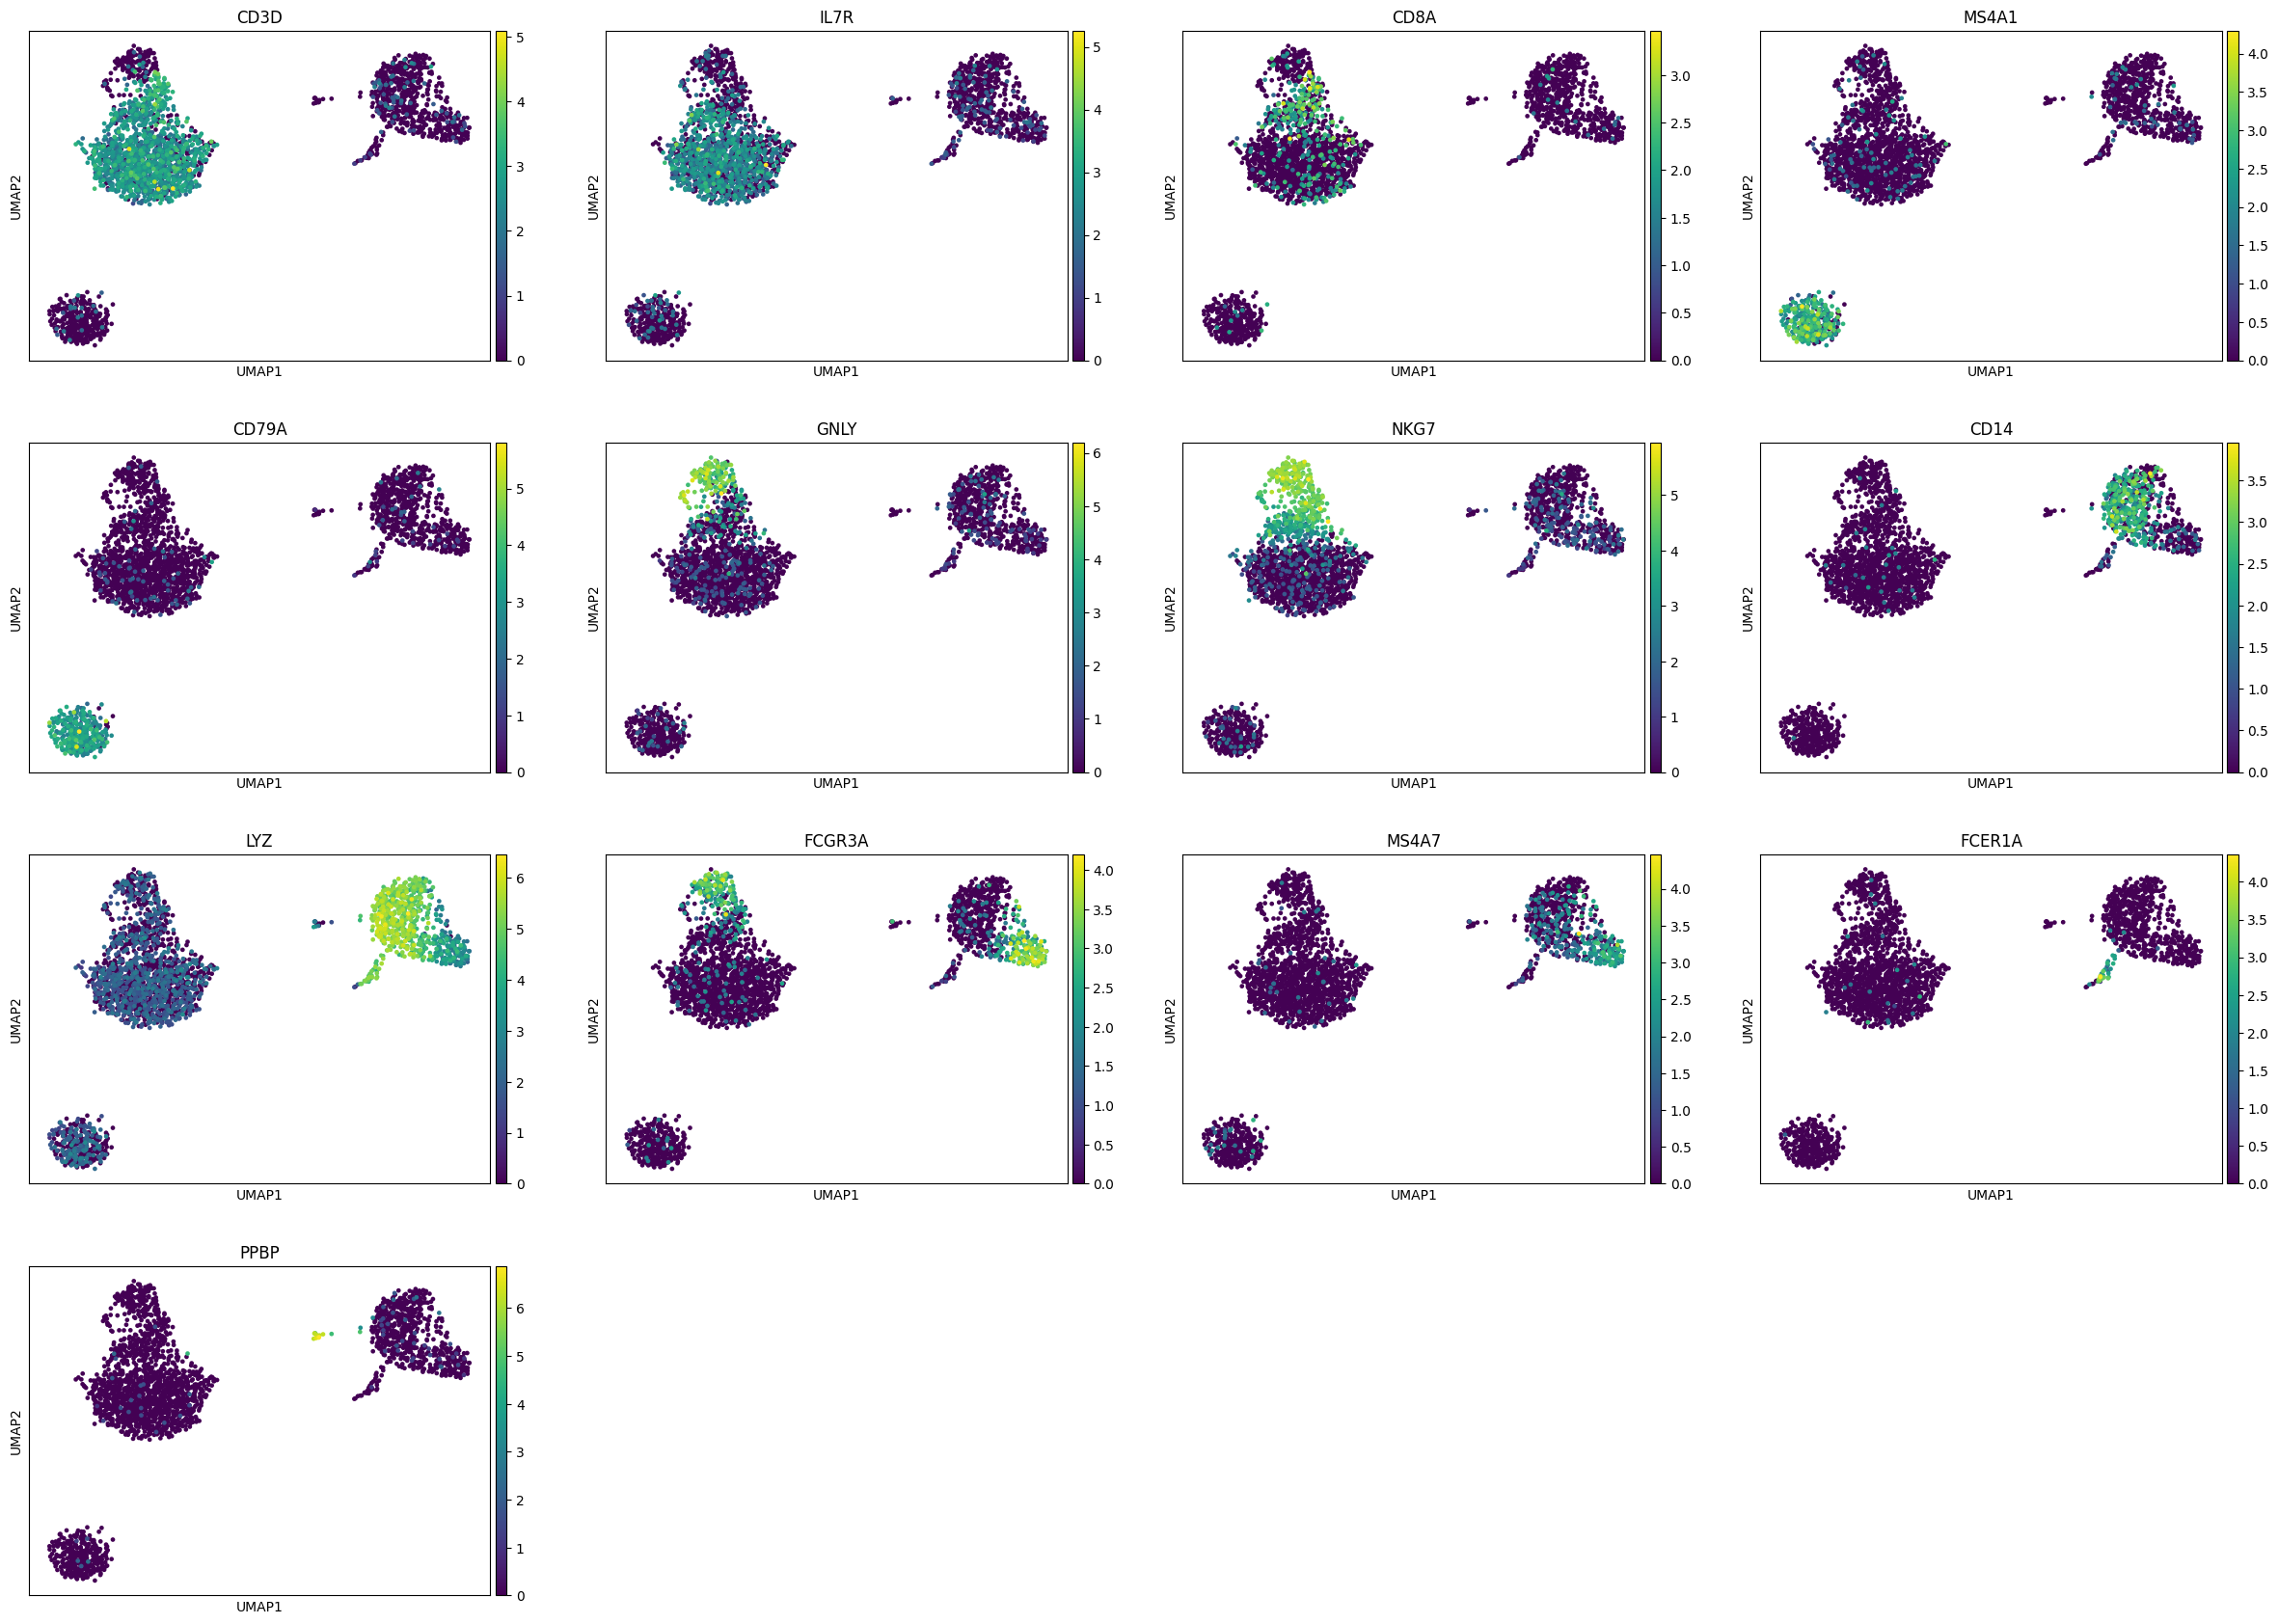

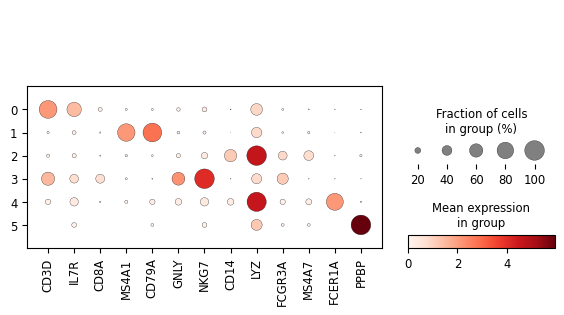

leiden,0,1,2,3,4,5
CD3D,0.88,0.06,0.09,0.59,0.18,0.00
IL7R,0.66,0.11,0.13,0.34,0.32,0.15
CD8A,0.12,0.03,0.02,0.35,0.03,0.00
MS4A1,0.05,0.86,0.06,0.05,0.09,0.00
CD79A,0.05,0.94,0.04,0.02,0.18,0.08
GNLY,0.10,0.08,0.13,0.57,0.24,0.00
NKG7,0.16,0.09,0.22,1.00,0.32,0.15
CD14,0.02,0.00,0.54,0.01,0.24,0.00
LYZ,0.50,0.43,1.00,0.41,0.97,0.46
FCGR3A,0.05,0.04,0.34,0.47,0.18,0.08


In [12]:
marker_genes = ['CD3D', 'IL7R', 'CD8A', 'MS4A1', 'CD79A', 'GNLY', 'NKG7',
                'CD14', 'LYZ', 'FCGR3A', 'MS4A7', 'FCER1A', 'PPBP']
sc.pl.umap(adata, color=marker_genes)
sc.pl.dotplot(adata, marker_genes, groupby='leiden')

# クラスターごとの発現細胞割合（dotplot の点の大きさに相当）
expr = sc.get.obs_df(adata, keys=['leiden'] + marker_genes, use_raw=True)
(expr.set_index('leiden') > 0).groupby(level=0, observed=True).mean().round(2).T

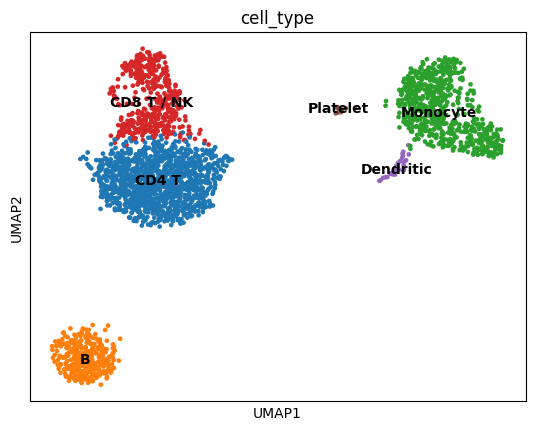

In [13]:
# アノテーションの割り当て（resolution=0.5 で得られた 6 クラスターに対応）
# 根拠は上の dotplot と発現細胞割合の表
cell_type_map = {
    '0': 'CD4 T',       # CD3D, IL7R
    '1': 'B',           # MS4A1, CD79A
    '2': 'Monocyte',    # CD14, LYZ（古典的）と FCGR3A, MS4A7（非古典的）が混在
    '3': 'CD8 T / NK',  # NKG7, GNLY．CD3D・CD8A を発現する細胞（CD8 T）も含む
    '4': 'Dendritic',   # FCER1A, CST3
    '5': 'Platelet',    # PPBP
}
# クラスター構成が変わると対応表は無効になるので確認する
assert set(cell_type_map) == set(adata.obs['leiden'].cat.categories), \
    f"Leiden クラスター {list(adata.obs['leiden'].cat.categories)} が対応表と一致しない"
adata.obs['cell_type'] = adata.obs['leiden'].map(cell_type_map)
sc.pl.umap(adata, color=['cell_type'], legend_loc='on data')

> **注意**：モジュール 4 の `resolution=0.5` では Leiden クラスターは 6 個になり，古典的単球（CD14+）と非古典的単球（FCGR3A+），CD8+ T 細胞と NK 細胞がそれぞれ 1 つのクラスターにまとまる．クラスター番号と細胞型の対応は，データ・パラメータ・ソフトウェアの版によって変わる．対応表は既存の例を流用せず，必ずマーカー遺伝子の発現から作り直す．`resolution` を大きくするとこれらのクラスターが分かれるかを確かめるのはよい演習である．

## モジュール 6：差次発現解析（DEG） — 負の二項分布モデル


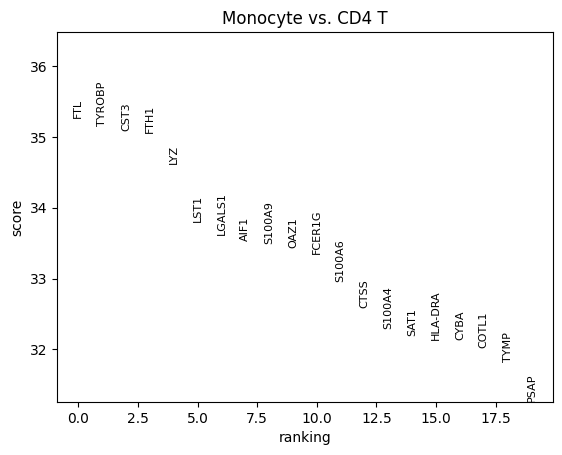

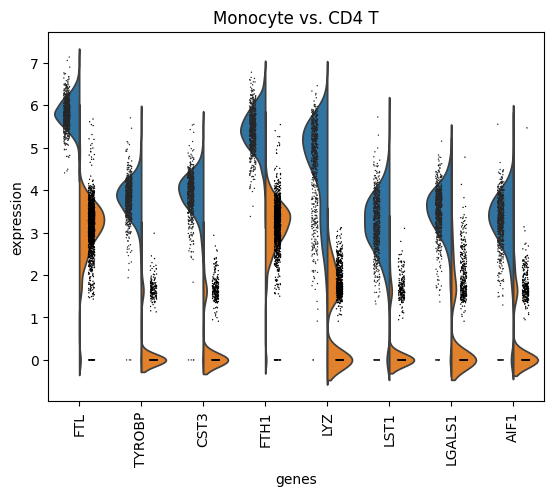

In [14]:

# 特定の 2 グループ間の DEG（Wilcoxon 検定）
sc.tl.rank_genes_groups(
    adata, groupby='cell_type',
    groups=['Monocyte'], reference='CD4 T',
    method='wilcoxon'
)
sc.pl.rank_genes_groups(adata, groups=['Monocyte'])
sc.pl.rank_genes_groups_violin(adata, groups='Monocyte', n_genes=8)


### 擬似バルク法（Pseudobulk）：集約の実習

複数サンプル（被験者）がある場合，同一サンプル・同一細胞型の細胞のカウントを足し合わせてからサンプル間で比較する（擬似バルク法）．同一被験者由来の細胞は独立ではないため，細胞を独立な観測として検定すると偽陽性が増える（擬似反復問題）\[Ref. 5\]．

**定式化．** 細胞 $i = 1, \dots, n$ のサンプルを $s(i)$，細胞型を $c(i)$ とし，組 $g = (s, c)$ をグループとする．グループ数を $k$ とし，所属行列 $A \in \{0, 1\}^{k \times n}$ を $A_{gi} = 1 \iff (s(i), c(i)) = g$ で定める．生カウント行列 $X \in \mathbb{Z}_{\geq 0}^{n \times m}$ に対し，擬似バルク行列は

$$Y = A X \in \mathbb{Z}_{\geq 0}^{k \times m}, \qquad Y_{gj} = \sum_{i \,:\, (s(i), c(i)) = g} X_{ij}$$

である．$A$ の各列はちょうど 1 つの成分が $1$ なので，$\mathbf{1}_k^\top Y = \mathbf{1}_n^\top X$（遺伝子ごとの総カウントは保存される）．

**注意．**

- 集約するのは **生カウント** である．この時点の `adata.X` は正規化・対数変換・HVG 抽出・スケーリング済みであり，足し合わせても意味がない．そこで生カウントを読み直す．
- PBMC 3k は **単一ドナー** 由来である．ここでは細胞を無作為に $K = 3$ 個の仮サンプルに割り当てるが，これは同一個体の技術的な分割にすぎず，生物学的反復ではない．したがって $Y$ を用いた差次発現検定は行わない（得られる $p$ 値は生物学的推論に使えない）．本来はドナーごとにサンプルを構成する．

In [15]:
import numpy as np
import pandas as pd
import scipy.sparse as sp

# 1. 生カウント行列を読み直し，QC 後の細胞に揃える
#    （この時点の adata.X は正規化・対数変換・HVG 抽出・スケーリング済みで，足し合わせても意味がない）
counts = sc.read_10x_mtx('data/filtered_gene_bc_matrices/hg19/', var_names='gene_symbols')
counts.var_names_make_unique()
counts = counts[adata.obs_names, :].copy()
counts.obs['cell_type'] = adata.obs['cell_type'].values

# 2. 細胞を無作為に K 個の仮サンプルに割り当てる（単一ドナーなので生物学的反復ではない）
K = 3
rng = np.random.default_rng(0)
counts.obs['sample'] = pd.Categorical([f'pseudo{s}' for s in rng.integers(K, size=counts.n_obs)])
print(pd.crosstab(counts.obs['sample'], counts.obs['cell_type']))

# 3. 所属行列 A ∈ {0,1}^{k×n}：A[g, i] = 1 ⇔ 細胞 i がグループ g = (sample, cell_type) に属する
keys = counts.obs['sample'].astype(str) + '|' + counts.obs['cell_type'].astype(str)
group = pd.Categorical(keys)
n = counts.n_obs
k = len(group.categories)
A = sp.csr_matrix((np.ones(n), (group.codes, np.arange(n))), shape=(k, n))

# 4. 擬似バルク行列 Y = A X（k × m）
X = counts.X  # n × m の生カウント（疎行列）
Y = (A @ X).toarray().astype(np.int64)
print(f'X: {X.shape}, A: {A.shape}, Y: {Y.shape}')

pseudobulk = pd.DataFrame(
    Y,
    index=pd.MultiIndex.from_tuples([tuple(g.split('|')) for g in group.categories],
                                    names=['sample', 'cell_type']),
    columns=counts.var_names,
)

# 5. 検算
assert Y.sum() == X.sum()                                   # 総カウントは保存される
n_cells = counts.obs.groupby(['sample', 'cell_type'], observed=True).size()
n_cells.index = n_cells.index.map(lambda t: tuple(map(str, t)))
assert (np.asarray(A.sum(axis=1)).ravel() == n_cells.loc[pseudobulk.index].values).all()  # A の行和 = 各グループの細胞数

agg = sc.get.aggregate(counts, by=['sample', 'cell_type'], func='sum')  # Scanpy 組み込み関数と一致するか
agg_sum = agg.layers['sum']
agg_df = pd.DataFrame(agg_sum.toarray() if sp.issparse(agg_sum) else np.asarray(agg_sum),
                      index=pd.MultiIndex.from_frame(agg.obs[['sample', 'cell_type']].astype(str)),
                      columns=agg.var_names)
assert (agg_df.loc[pseudobulk.index].values == Y).all()
print('検算 OK')

print(f'ゼロ成分の割合: X = {1 - X.nnz / np.prod(X.shape):.3f}, Y = {(Y == 0).mean():.3f}')
pseudobulk[['LYZ', 'CD14', 'MS4A1', 'CD79A', 'IL7R', 'NKG7']]

cell_type  CD4 T    B  Monocyte  CD8 T / NK  Dendritic  Platelet
sample                                                          
pseudo0      389  106       208         127          8         4
pseudo1      392  111       218         155         11         4
pseudo2      411  124       215         135         15         5
X: (2638, 32738), A: (18, 2638), Y: (18, 32738)
検算 OK
ゼロ成分の割合: X = 0.974, Y = 0.740


LYZ  CD14  MS4A1  CD79A  IL7R  NKG7
sample  cell_type                                       
pseudo0 B             59     0    233    481    24     9
        CD4 T        304     6     25     21   634   102
        CD8 T / NK    70     2      7      9    79  2032
        Dendritic    621     2      0      2     4     4
        Monocyte    7439   261     12      9    21    83
        Platelet       2     0      0      0     0     1
pseudo1 B             81     1    276    481    18     8
        CD4 T        278     8     23     20   640   131
        CD8 T / NK    77     2      6      2   166  2220
        Dendritic    675     4      2      0     4     7
        Monocyte    8537   305     11      8    41    94
        Platelet      11     0      0      1     2     1
pseudo2 B             75     0    243    516     9    18
        CD4 T        275     7     17     21   662    78
        CD8 T / NK    84     1      8      2    96  2111
        Dendritic    993     4      1     11     5     3
        Monocyte    7872   263     18     10    31    56
        Platelet       4     0      0      0     0     0

## モジュール 7：発展 — 軌跡推定と擬似時間


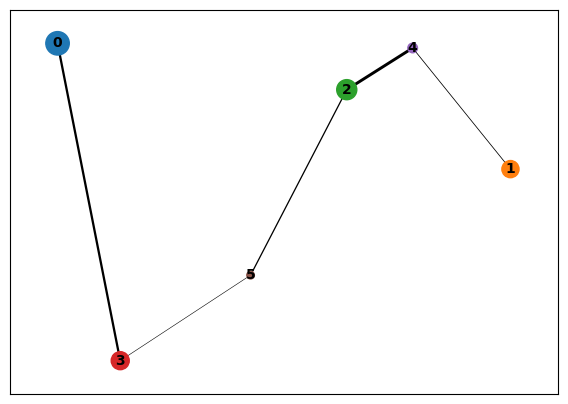

In [16]:

sc.tl.paga(adata, groups='leiden')
sc.pl.paga(adata, plot=True, threshold=0.03)


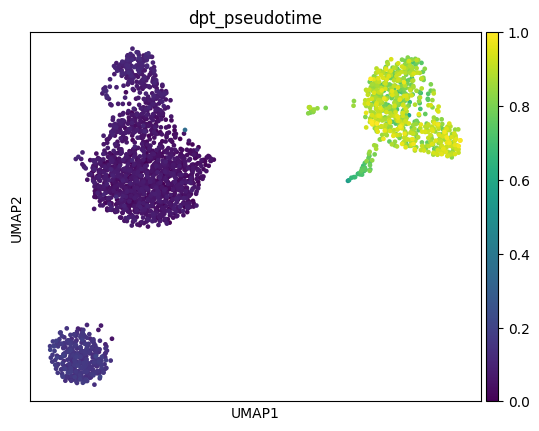

In [17]:

import numpy as np

# 根細胞（幹細胞に近い細胞）を指定
adata.uns['iroot'] = np.flatnonzero(adata.obs['leiden'] == '0')[0]
sc.tl.diffmap(adata)  # 拡散写像（DPT の前提）を先に計算する
sc.tl.dpt(adata)
sc.pl.umap(adata, color=['dpt_pseudotime'], color_map='viridis')


Filtered out 20801 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.


computing moments based on connectivities


    finished (0:00:01) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/8 cores)


  0%|          | 0/2578 [00:00<?, ?gene/s]

    finished (0:10:41) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities


    finished (0:00:04) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/8 cores)


  0%|          | 0/3696 [00:00<?, ?cells/s]

    finished (0:00:09) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding


    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


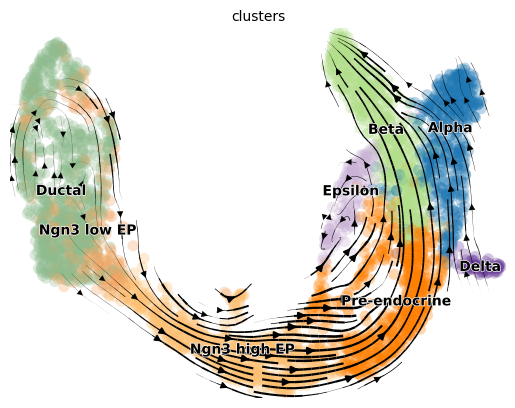

In [18]:
import scvelo as scv

# scVelo サンプルデータ（膵臓β細胞分化）を使用
# unspliced / spliced カウントが含まれた AnnData が返される
adata_velo = scv.datasets.pancreas()

scv.pp.filter_and_normalize(adata_velo, min_shared_counts=20)
# 近傍グラフは Scanpy で先に作る（scVelo による自動計算は非推奨）
sc.pp.pca(adata_velo, n_comps=30)
sc.pp.neighbors(adata_velo, n_neighbors=30, n_pcs=30)
scv.pp.moments(adata_velo, n_pcs=None, n_neighbors=None)

# dynamical モデルの前に splicing dynamics を推定する
scv.tl.recover_dynamics(adata_velo)
scv.tl.velocity(adata_velo, mode='dynamical')
scv.tl.velocity_graph(adata_velo)
scv.pl.velocity_embedding_stream(adata_velo, basis='umap', color='clusters')
